## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from scipy.stats import zscore
from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


## Generate Patient Health Records Dataset

In [2]:
n = 1000

df = pd.DataFrame({
    "patient_id": [f"P{i:04d}" for i in range(1, n + 1)],

    "age": np.random.randint(18, 90, n),

    "gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "region": np.random.choice(
        ["North", "South", "East", "West"], n
    ),

    "bmi": np.random.normal(25, 4, n).round(2),

    "blood_pressure": np.random.normal(120, 15, n).round(2),

    "cholesterol": np.random.normal(190, 30, n).round(2),

    "glucose": np.random.normal(100, 20, n).round(2),

    "disease_risk": np.random.choice(
        [0, 1], n, p=[0.7, 0.3]
    )
})

# Add some extreme outliers intentionally
df.loc[np.random.choice(df.index, 15, replace=False), "bmi"] = np.random.uniform(45, 65, 15)

df.loc[np.random.choice(df.index, 15, replace=False), "blood_pressure"] = np.random.uniform(180, 240, 15)

df.loc[np.random.choice(df.index, 15, replace=False), "cholesterol"] = np.random.uniform(300, 450, 15)

df.loc[np.random.choice(df.index, 15, replace=False), "glucose"] = np.random.uniform(200, 350, 15)

print("Dataset generated successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset generated successfully!
Dataset Shape: (1000, 9)


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,P0001,69,Male,South,27.64,119.97,175.88,83.61,1
1,P0002,32,Male,West,30.74,139.08,233.51,116.87,0
2,P0003,89,Female,East,25.65,102.70,218.58,103.44,0
3,P0004,78,Male,North,21.57,121.70,244.91,118.37,0
4,P0005,38,Male,West,24.29,114.05,205.87,120.51,0


## Introduce Missing Values

In [3]:
missing_columns = [
    "age",
    "gender",
    "region",
    "bmi",
    "cholesterol",
    "glucose"
]

for col in missing_columns:
    missing_indices = np.random.choice(
        df.index,
        size=int(0.10 * len(df)),
        replace=False
    )

    df.loc[missing_indices, col] = np.nan

print("Missing values added successfully!")

display(df.head(10))

Missing values added successfully!


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,P0001,69.0,Male,South,27.64,119.970000,175.88,83.61,1
1,P0002,32.0,Male,West,30.74,139.080000,233.51,116.87,0
2,P0003,89.0,Female,East,25.65,102.700000,218.58,103.44,0
3,P0004,78.0,Male,North,21.57,121.700000,244.91,118.37,0
4,P0005,38.0,NaN,West,NaN,114.050000,205.87,120.51,0
5,P0006,41.0,Male,South,29.07,140.950000,191.71,NaN,0
6,P0007,20.0,Male,East,25.82,142.490000,NaN,117.63,0
7,P0008,39.0,Female,South,20.18,120.010000,159.39,99.72,1
8,P0009,70.0,Male,North,27.39,206.023422,152.16,96.83,0
9,P0010,19.0,NaN,East,28.08,126.410000,205.22,125.05,1


## Missing Values Summary Report

In [4]:
missing_count = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

print("Missing Values Summary")
display(missing_report)

Missing Values Summary


,Missing Count,Missing Percentage
patient_id,0,0.0
age,100,10.0
gender,100,10.0
region,100,10.0
bmi,100,10.0
blood_pressure,0,0.0
cholesterol,100,10.0
glucose,100,10.0
disease_risk,0,0.0


## Part A — Handling Missing Values

In [5]:
numeric_cols = [
    "age",
    "bmi",
    "blood_pressure",
    "cholesterol",
    "glucose"
]

categorical_cols = [
    "gender",
    "region"
]

print("Numerical Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['age', 'bmi', 'blood_pressure', 'cholesterol', 'glucose']
Categorical Columns: ['gender', 'region']


In [6]:
df_mean = df.copy()
df_median = df.copy()

mean_imputer = SimpleImputer(strategy="mean")

df_mean[["bmi"]] = mean_imputer.fit_transform(
    df_mean[["bmi"]])

median_imputer = SimpleImputer(strategy="median")

df_median[["bmi"]] = median_imputer.fit_transform(
    df_median[["bmi"]])

print("BMI Mean Imputation:")
display(df_mean[["bmi"]].head())

print("BMI Median Imputation:")
display(df_median[["bmi"]].head())

BMI Mean Imputation:


,bmi
0,27.640000
1,30.740000
2,25.650000
3,21.570000
4,25.506566


BMI Median Imputation:


,bmi
0,27.640
1,30.740
2,25.650
3,21.570
4,25.285


## Simple Imputer: Most Frequent

In [7]:
df_most_frequent = df.copy()

most_frequent_imputer = SimpleImputer(
    strategy="most_frequent")

df_most_frequent[categorical_cols] = (
    most_frequent_imputer.fit_transform(
        df_most_frequent[categorical_cols]
    )
)

print("Most Frequent Imputation:")
display(df_most_frequent[categorical_cols].head())

Most Frequent Imputation:


,gender,region
0,Male,South
1,Male,West
2,Female,East
3,Male,North
4,Male,West


## Missing Indicator + Random Sample Imputation

In [8]:
df_random = df.copy()

for col in missing_columns:
    df_random[col + "_missing"] = (
        df_random[col].isnull().astype(int)
    )

    missing_mask = df_random[col].isnull()

    observed_values = df_random[col].dropna()

    random_values = np.random.choice(
        observed_values,
        size=missing_mask.sum(),
        replace=True
    )

    df_random.loc[missing_mask, col] = random_values

print("Random Sample Imputation Completed!")

display(df_random.head())

Random Sample Imputation Completed!


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk,age_missing,gender_missing,region_missing,bmi_missing,cholesterol_missing,glucose_missing
0,P0001,69.0,Male,South,27.64,119.97,175.88,83.61,1,0,0,0,0,0,0
1,P0002,32.0,Male,West,30.74,139.08,233.51,116.87,0,0,0,0,0,0,0
2,P0003,89.0,Female,East,25.65,102.70,218.58,103.44,0,0,0,0,0,0,0
3,P0004,78.0,Male,North,21.57,121.70,244.91,118.37,0,0,0,0,0,0,0
4,P0005,38.0,Male,West,22.52,114.05,205.87,120.51,0,0,1,0,1,0,0


## KNN Imputer

In [9]:
df_knn = df.copy()

knn_imputer = KNNImputer(n_neighbors=5)

df_knn[numeric_cols] = knn_imputer.fit_transform(
    df_knn[numeric_cols])

print("KNN Imputation Completed!")

display(df_knn[numeric_cols].head())

KNN Imputation Completed!


,age,bmi,blood_pressure,cholesterol,glucose
0,69.0,27.640000,119.97,175.88,83.61
1,32.0,30.740000,139.08,233.51,116.87
2,89.0,25.650000,102.70,218.58,103.44
3,78.0,21.570000,121.70,244.91,118.37
4,38.0,32.703023,114.05,205.87,120.51


## MICE Algorithm

In [11]:
df_mice = df.copy()

mice_imputer = IterativeImputer(
    max_iter=10,
    random_state=42
)

df_mice[numeric_cols] = mice_imputer.fit_transform(
    df_mice[numeric_cols]
)

print("MICE Imputation Completed!")

display(df_mice[numeric_cols].head())

MICE Imputation Completed!


,age,bmi,blood_pressure,cholesterol,glucose
0,69.0,27.640000,119.97,175.88,83.61
1,32.0,30.740000,139.08,233.51,116.87
2,89.0,25.650000,102.70,218.58,103.44
3,78.0,21.570000,121.70,244.91,118.37
4,38.0,25.557724,114.05,205.87,120.51


In [12]:
imputation_comparison = pd.DataFrame({
    "Original Missing": df[ numeric_cols ].isnull().sum(),

    "Mean Imputation": df_mean[numeric_cols].isnull().sum(),

    "Median Imputation": df_median[numeric_cols].isnull().sum(),

    "KNN Imputation": df_knn[numeric_cols].isnull().sum(),

    "MICE Imputation": df_mice[numeric_cols].isnull().sum()
})

print("Imputation Comparison")
display(imputation_comparison)

Imputation Comparison


,Original Missing,Mean Imputation,Median Imputation,KNN Imputation,MICE Imputation
age,100,100,100,0,0
bmi,100,0,0,0,0
blood_pressure,0,0,0,0,0
cholesterol,100,100,100,0,0
glucose,100,100,100,0,0


## Part B — Handling Outliers

## Before Outlier Treatment Summary

In [13]:
outlier_cols = [
    "bmi",
    "blood_pressure",
    "cholesterol",
    "glucose"
]

before_outlier_summary = df[outlier_cols].describe().T

print("Before Outlier Treatment")
display(before_outlier_summary)

Before Outlier Treatment


,count,mean,std,min,25%,50%,75%,max
bmi,900.0,25.506566,5.316627,11.45,22.4600,25.285,27.8675,64.376329
blood_pressure,1000.0,121.361962,17.939743,69.91,110.3200,120.310,131.0825,232.825314
cholesterol,900.0,192.022091,37.209943,98.62,168.9800,190.305,211.5425,423.331673
glucose,900.0,103.359034,28.695243,37.37,87.5725,100.850,114.7075,333.911381


## Z-Score Method

In [14]:
df_zscore = df.copy()

z_cols = ["cholesterol", "glucose"]

z_values = np.abs(
    zscore(df_zscore[z_cols], nan_policy="omit"))

z_mask = (z_values < 3).all(axis=1)

df_zscore = df_zscore.loc[z_mask].copy()

print("Z-Score Outlier Treatment Completed")
print("Original Shape:", df.shape)
print("After Z-Score Shape:", df_zscore.shape)

Z-Score Outlier Treatment Completed
Original Shape: (1000, 9)
After Z-Score Shape: (791, 9)


## IQR Method

In [15]:
df_iqr = df.copy()

col = "bmi"

Q1 = df_iqr[col].quantile(0.25)
Q3 = df_iqr[col].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_iqr = df_iqr[
    (df_iqr[col].isna()) |
    (
        (df_iqr[col] >= lower_bound) &
        (df_iqr[col] <= upper_bound)
    )
].copy()

print("IQR Outlier Treatment Completed")
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Original Shape:", df.shape)
print("After IQR Shape:", df_iqr.shape)

IQR Outlier Treatment Completed
Lower Bound: 14.348750000000003
Upper Bound: 35.97875
Original Shape: (1000, 9)
After IQR Shape: (982, 9)


## Percentile Method

In [16]:
df_percentile = df.copy()

for col in outlier_cols:

    lower = df_percentile[col].quantile(0.01)
    upper = df_percentile[col].quantile(0.99)

    df_percentile[col] = df_percentile[col].clip(
        lower=lower,
        upper=upper
    )

print("Percentile Capping Completed!")

display(df_percentile[outlier_cols].describe().T)

Percentile Capping Completed!


,count,mean,std,min,25%,50%,75%,max
bmi,900.0,25.424142,4.706745,15.3668,22.4600,25.285,27.8675,48.435594
blood_pressure,1000.0,121.228835,17.016893,83.8673,110.3200,120.310,131.0825,192.832626
cholesterol,900.0,191.531332,34.289273,117.8971,168.9800,190.305,211.5425,328.352761
glucose,900.0,102.973302,25.515087,58.1220,87.5725,100.850,114.7075,245.001035


## Winsorization

In [17]:
df_winsor = df.copy()

for col in outlier_cols:

    lower = df_winsor[col].quantile(0.05)
    upper = df_winsor[col].quantile(0.95)

    df_winsor[col] = df_winsor[col].clip(
        lower=lower,
        upper=upper
    )

print("Winsorization Completed!")

display(df_winsor[outlier_cols].describe().T)

Winsorization Completed!


,count,mean,std,min,25%,50%,75%,max
bmi,900.0,25.217114,3.615553,18.9000,22.4600,25.285,27.8675,31.8905
blood_pressure,1000.0,120.614355,13.966071,95.0585,110.3200,120.310,131.0825,145.4070
cholesterol,900.0,190.225328,28.625225,137.9150,168.9800,190.305,211.5425,243.1420
glucose,900.0,101.485836,18.621310,68.8755,87.5725,100.850,114.7075,137.1630


## Compare Outlier Methods

In [18]:
outlier_comparison = pd.DataFrame({
    "Original Rows": [len(df)],
    "Z-Score Rows": [len(df_zscore)],
    "IQR Rows": [len(df_iqr)],
    "Percentile Rows": [len(df_percentile)],
    "Winsorization Rows": [len(df_winsor)]
})

print("Outlier Method Comparison")
display(outlier_comparison)

Outlier Method Comparison


,Original Rows,Z-Score Rows,IQR Rows,Percentile Rows,Winsorization Rows
0,1000,791,982,1000,1000


## Before vs After Visualization

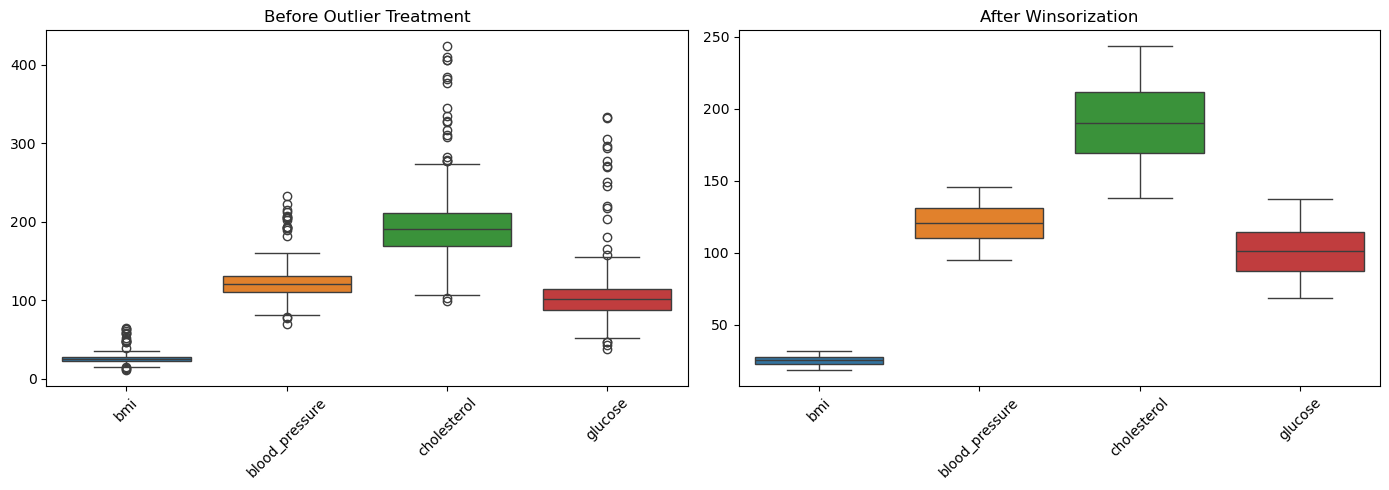

In [19]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df[outlier_cols])
plt.title("Before Outlier Treatment")
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(data=df_winsor[outlier_cols])
plt.title("After Winsorization")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Part C — Final Clean Dataset

## Create Final Clean Dataset

In [20]:
final_df = df.copy()

num_imputer = SimpleImputer(strategy="median")

final_df[numeric_cols] = num_imputer.fit_transform(
    final_df[numeric_cols]
)

cat_imputer = SimpleImputer(strategy="most_frequent")

final_df[categorical_cols] = cat_imputer.fit_transform(
    final_df[categorical_cols]
)

for col in outlier_cols:

    lower = final_df[col].quantile(0.05)
    upper = final_df[col].quantile(0.95)

    final_df[col] = final_df[col].clip(
        lower=lower,
        upper=upper
    )

print("Final Clean Dataset Created!")
print("Final Shape:", final_df.shape)

display(final_df.head())

Final Clean Dataset Created!
Final Shape: (1000, 9)


,patient_id,age,gender,region,bmi,blood_pressure,cholesterol,glucose,disease_risk
0,P0001,69.0,Male,South,27.640,119.97,175.880,83.61,1
1,P0002,32.0,Male,West,30.740,139.08,233.510,116.87,0
2,P0003,89.0,Female,East,25.650,102.70,218.580,103.44,0
3,P0004,78.0,Male,North,21.570,121.70,240.769,118.37,0
4,P0005,38.0,Male,West,25.285,114.05,205.870,120.51,0


In [21]:
print("Missing Values in Final Dataset:")
display(final_df.isnull().sum())

if final_df.isnull().sum().sum() == 0:
    print("No missing values remaining!")
else:
    print("Some missing values still remain.")

Missing Values in Final Dataset:


patient_id        0
age               0
gender            0
region            0
bmi               0
blood_pressure    0
cholesterol       0
glucose           0
disease_risk      0
dtype: int64

No missing values remaining!


In [22]:
print("Final Dataset Summary:")
display(final_df.describe(include="all").T)

Final Dataset Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
patient_id,1000,1000,P1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1000.0,NaN,NaN,NaN,52.918,19.805543,18.0,36.75,53.0,69.0,89.0
gender,1000,2,Male,554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1000,4,North,335,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1000.0,NaN,NaN,NaN,25.23036,3.39489,19.169,22.7425,25.285,27.525,31.76
blood_pressure,1000.0,NaN,NaN,NaN,120.614355,13.966071,95.0585,110.32,120.31,131.0825,145.407
cholesterol,1000.0,NaN,NaN,NaN,190.21764,26.747884,139.986,171.6175,190.305,209.4425,240.769
glucose,1000.0,NaN,NaN,NaN,101.401565,17.375135,70.2475,89.1525,100.85,113.215,135.351
disease_risk,1000.0,NaN,NaN,NaN,0.319,0.466322,0.0,0.0,0.0,1.0,1.0


In [23]:
final_df.to_csv(
    "patient_health_records_cleaned.csv",
    index=False
)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


## . Profiling Report

In [24]:
from ydata_profiling import ProfileReport

profile = ProfileReport(
    final_df,
    title="Patient Health Records - Final Data Profiling Report",
    explorative=True
)

profile.to_file("patient_health_profiling_report.html")

print("Profiling report generated successfully!")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:00<00:00, 144.55it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report generated successfully!
